# 02 - Seasonal Concentration and Anomaly Detection
**Questions**
1. Is tourism demand concentrated in particular months? Which destinations are most seasonal?
2. Do domestic and inbound tourism have different seasonal patterns?
3. Which months are peak / low-demand months for each destination?
4. Which observations are *unusual* after accounting for normal seasonality and trend?

Course topics used: grouping and aggregation, mean / standard deviation, proportions,
standardisation (z-scores), outliers, visualisation (heatmaps, box plots, line charts).

We do not assume an imbalance exists; we measure it.

## 0. Setup (works in Google Colab and on a local computer)

**Google Colab:** run the cell below. It downloads the project from GitHub
(set `REPO_URL` to your repository). If you do not use GitHub, upload the
whole `CS316_Tourism_Project` folder to Google Drive instead and set
`DRIVE_PATH`; the cell will mount Drive and use that folder.

**Locally:** just run the cell; it finds the project folder automatically.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/<your-username>/CS316_Tourism_Project.git"  # <- edit
DRIVE_PATH = "/content/drive/MyDrive/CS316_Tourism_Project"                # <- or edit

if "google.colab" in sys.modules:                      # running inside Colab
    if "<your-username>" not in REPO_URL:              # option A: clone from GitHub
        if not Path("/content/CS316_Tourism_Project").exists():
            subprocess.run(["git", "clone", REPO_URL, "/content/CS316_Tourism_Project"], check=True)
        os.chdir("/content/CS316_Tourism_Project")
    else:                                              # option B: Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir(DRIVE_PATH)
elif Path.cwd().name == "notebooks":                   # local run from notebooks/
    os.chdir("..")

PROJECT = Path.cwd()                                   # project root folder
sys.path.insert(0, str(PROJECT / "src"))               # so we can `import tourism`
FIG = PROJECT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
OUT = PROJECT / "outputs"
print("Project folder:", PROJECT)

Project folder: /home/user/CS316_Tourism_Project


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import tourism as t

sns.set_theme(style="whitegrid")
dests, totals = t.load_tourism()
dests = t.optimize_memory(dests)

# Only series observed (and > 0) in all 60 months, see notebook 01 section 4.
elig = t.eligible_series(dests)
panel = dests.set_index(["tourist_type", "destination"]).loc[elig].reset_index()
panel["tourists"] = panel["tourists"].astype(float)
panel["series"] = panel["tourist_type"].astype(str) + " | " + panel["destination"].astype(str)
print("Series analysed:", panel["series"].nunique())

Series analysed: 52


## 1. Measuring seasonal concentration
For each series and year we look at its 12 monthly values and compute three simple measures:
* **Coefficient of variation (CV)** = standard deviation / mean of the 12 months.
  0 means every month is the same; 0.5 means months typically differ from the average
  month by 50%. Dividing by the mean lets us compare big and small destinations.
* **Top-3 share** - share of the year's tourists arriving in the 3 busiest months.
  With perfectly even demand it is 3/12 = **25%**.
* **Peak/low ratio** - busiest month divided by quietest month (1 = even).

2021 is affected by COVID-19 travel restrictions and 2022 by the recovery of
inbound travel, so the main summary uses **2023-2025** ("normal" years).

In [3]:
def concentration(values):
    """Concentration measures for the 12 monthly values of one year."""
    v = np.sort(np.asarray(values, dtype=float))[::-1]       # largest first
    return pd.Series({"cv": v.std() / v.mean(),               # coefficient of variation
                      "top3_share_%": v[:3].sum() / v.sum() * 100,
                      "peak_low_ratio": v[0] / v[-1]})

conc_year = (panel.groupby(["tourist_type", "destination", "year"], observed=True)["tourists"]
                  .apply(concentration).unstack().reset_index())
conc = (conc_year[conc_year.year >= 2023]
        .groupby(["tourist_type", "destination"], observed=True)[["cv", "top3_share_%", "peak_low_ratio"]]
        .mean().reset_index())
volume = panel[panel.year >= 2023].groupby(["tourist_type", "destination"], observed=True)["tourists"].sum() / 3
conc = conc.merge(volume.rename("avg_yearly_tourists").reset_index())
conc[["tourist_type", "destination"]] = conc[["tourist_type", "destination"]].astype(str)
conc.sort_values("cv", ascending=False).head(10).round(3)

,tourist_type,destination,cv,top3_share_%,peak_low_ratio,avg_yearly_tourists
2,Domestic,Al Bahah,0.850,58.048,7.847,711992.667
8,Domestic,BILJURASHI,0.825,53.786,22.705,141575.667
19,Domestic,Other AlBaha,0.629,46.276,9.096,256556.333
0,Domestic,Abha,0.602,48.406,4.825,2564056.333
44,Inbound,Buraydah,0.515,42.363,8.184,175425.667
23,Domestic,Other Jazan,0.463,42.433,4.707,2121011.667
15,Domestic,Khamis Mushait,0.459,41.949,3.314,1363378.000
36,Domestic,Taif,0.446,42.609,3.735,3392346.667
32,Domestic,Rass,0.444,40.022,8.048,243791.000
25,Domestic,Other Madinah,0.430,40.711,5.034,307238.667


                 cv  top3_share_%  peak_low_ratio
tourist_type                                     
Domestic      0.206        32.368           2.079
Inbound       0.323        35.483           3.145


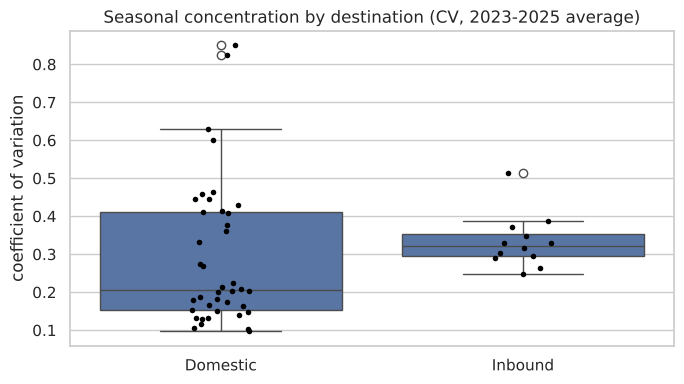

In [4]:
# Domestic vs inbound: distribution of the CV over destinations
print(conc.groupby("tourist_type")[["cv", "top3_share_%", "peak_low_ratio"]].median().round(3))
plt.figure(figsize=(7, 4))
sns.boxplot(data=conc, x="tourist_type", y="cv")
np.random.seed(42)                                  # fixed jitter of the dots
sns.stripplot(data=conc, x="tourist_type", y="cv", color="black", size=4)
plt.title("Seasonal concentration by destination (CV, 2023-2025 average)")
plt.ylabel("coefficient of variation"); plt.xlabel("")
plt.tight_layout(); plt.savefig(FIG / "02_cv_by_type.png", dpi=200); plt.show()

In [5]:
# National level (official totals): concentration per year
nat_conc = (totals.groupby(["tourist_type", "year"])["tourists"].apply(concentration)
                  .unstack().round(3))
nat_conc

cv  top3_share_%  peak_low_ratio
tourist_type year                                     
Domestic     2021  0.210        32.857           1.808
             2022  0.289        34.055           2.677
             2023  0.176        31.600           1.908
             2024  0.148        29.693           1.659
             2025  0.107        28.525           1.427
Inbound      2021  0.565        47.107           5.530
             2022  0.369        36.041           4.355
             2023  0.207        31.432           2.151
             2024  0.229        31.764           2.102
             2025  0.298        33.903           4.806

## 2. Seasonal profiles: peak and low-demand months
The **seasonal index** of a month = average share of the year in that month x 12.
An index of 1.0 is an average month; 1.5 means 50% busier than average.
Using shares of each year removes the growth between years.

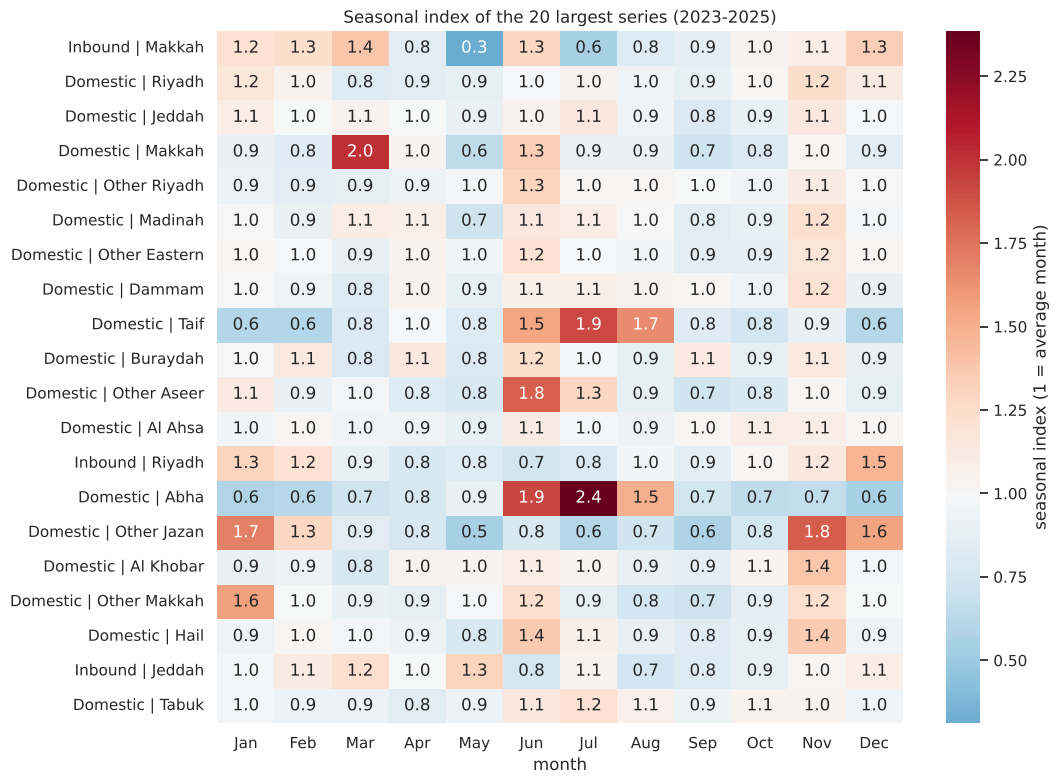

In [6]:
panel["share"] = panel["tourists"] / panel.groupby(["series", "year"])["tourists"].transform("sum")
season = (panel[panel.year >= 2023].groupby(["series", "month"])["share"].mean() * 12).unstack()
order = conc.assign(series=conc.tourist_type + " | " + conc.destination) \
            .sort_values("avg_yearly_tourists", ascending=False)["series"]
top20 = [s for s in order if s in season.index][:20]
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.figure(figsize=(11, 8))
sns.heatmap(season.loc[top20], annot=True, fmt=".1f", cmap="RdBu_r", center=1,
            xticklabels=month_names, cbar_kws={"label": "seasonal index (1 = average month)"})
plt.title("Seasonal index of the 20 largest series (2023-2025)"); plt.ylabel("")
plt.tight_layout(); plt.savefig(FIG / "02_seasonal_index_heatmap.png", dpi=200); plt.show()

In [7]:
# Peak and low months per series (largest and smallest seasonal index)
peaks = pd.DataFrame({
    "peak_month": season.idxmax(axis=1).map(lambda m: month_names[m - 1]),
    "peak_index": season.max(axis=1),
    "low_month": season.idxmin(axis=1).map(lambda m: month_names[m - 1]),
    "low_index": season.min(axis=1)}).loc[top20].round(2)
peaks

,peak_month,peak_index,low_month,low_index
series,,,,
Inbound | Makkah,Mar,1.38,May,0.31
Domestic | Riyadh,Nov,1.24,Mar,0.81
Domestic | Jeddah,Nov,1.15,Sep,0.80
Domestic | Makkah,Mar,2.01,May,0.65
Domestic | Other Riyadh,Jun,1.31,Feb,0.86
Domestic | Madinah,Nov,1.23,May,0.72
Domestic | Other Eastern,Jun,1.22,Sep,0.86
Domestic | Dammam,Nov,1.21,Mar,0.81
Domestic | Taif,Jul,1.91,Feb,0.60


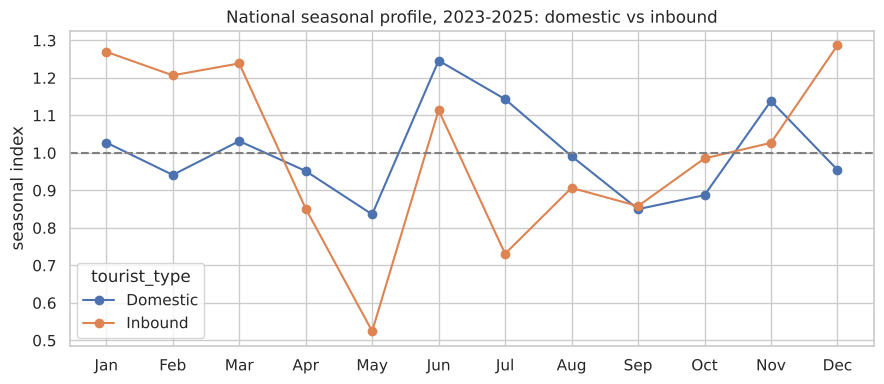

month,1,2,3,4,5,6,7,8,9,10,11,12
tourist_type,,,,,,,,,,,,
Domestic,1.03,0.94,1.03,0.95,0.84,1.25,1.14,0.99,0.85,0.89,1.14,0.95
Inbound,1.27,1.21,1.24,0.85,0.52,1.11,0.73,0.91,0.86,0.99,1.03,1.29


In [8]:
# Domestic vs inbound national seasonal profile
nat = totals[totals.year >= 2023].copy()
nat["share"] = nat["tourists"] / nat.groupby(["tourist_type", "year"])["tourists"].transform("sum")
prof = nat.groupby(["tourist_type", "month"])["share"].mean().unstack(0) * 12
ax = prof.plot(marker="o", figsize=(9, 4))
ax.axhline(1, color="grey", ls="--"); ax.set_xticks(range(1, 13), month_names)
ax.set_ylabel("seasonal index"); ax.set_xlabel("")
ax.set_title("National seasonal profile, 2023-2025: domestic vs inbound")
plt.tight_layout(); plt.savefig(FIG / "02_national_profile.png", dpi=200); plt.show()
prof.round(2).T

**Is the peak month the same every year?** If a destination is truly seasonal, its busiest
month should repeat. We count how often the most common peak month occurred in 2022-2025.

In [9]:
peak_by_year = (panel[panel.year >= 2022].loc[lambda d: d.groupby(["series", "year"])["tourists"].idxmax()]
                [["series", "tourist_type", "year", "month"]])
repeat = (peak_by_year.groupby(["series", "tourist_type"])["month"]
          .agg(lambda m: m.value_counts().iloc[0]).rename("years_with_same_peak").reset_index())
print("Number of years (out of 4) in which the most common peak month was the peak:")
print(pd.crosstab(repeat["tourist_type"], repeat["years_with_same_peak"]))

Number of years (out of 4) in which the most common peak month was the peak:
years_with_same_peak  1   2  3  4
tourist_type                     
Domestic              5  29  5  1
Inbound               5   4  2  1


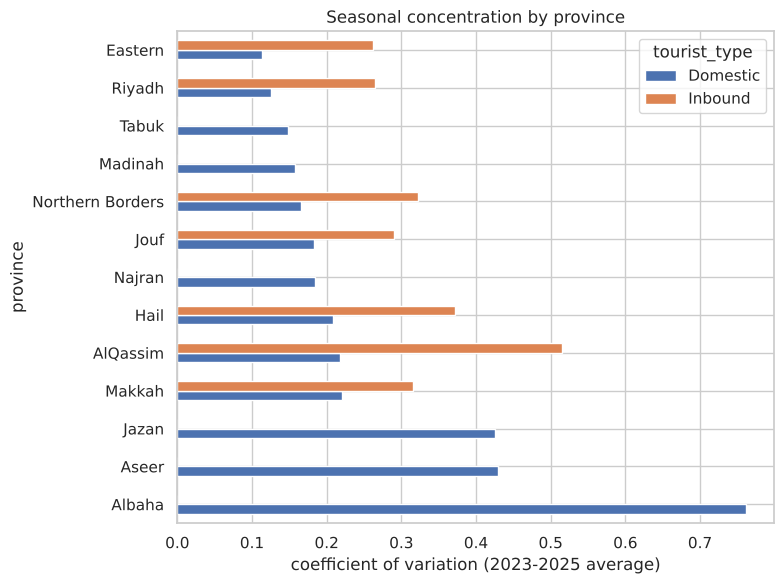

tourist_type,Domestic,Inbound
province,,
AlQassim,0.218,0.515
Albaha,0.761,NaN
Aseer,0.430,NaN
Eastern,0.114,0.262
Hail,0.208,0.372
Jazan,0.426,NaN
Jouf,0.183,0.290
Madinah,0.157,NaN
Makkah,0.220,0.316


In [10]:
# Regional comparison: CV per province (eligible series summed by province)
prov_month = (panel[panel.year >= 2023]
              .groupby(["tourist_type", "province", "year", "month"], observed=True)["tourists"].sum())
prov_tab = (prov_month.groupby(["tourist_type", "province", "year"], observed=True)
                      .apply(lambda v: v.std(ddof=0) / v.mean())
                      .groupby(["province", "tourist_type"], observed=True).mean().unstack().round(3))
prov_tab.sort_values("Domestic", ascending=False).plot.barh(figsize=(8, 6))
plt.xlabel("coefficient of variation (2023-2025 average)"); plt.title("Seasonal concentration by province")
plt.tight_layout(); plt.savefig(FIG / "02_cv_by_province.png", dpi=200); plt.show()
prov_tab

## 3. Anomaly detection with z-scores
An anomaly is a month that is unusual **after** removing what is normal for that
destination: its yearly level (trend) and its usual month pattern (seasonality).
Ordinary summer peaks are therefore *not* anomalies. Missing months are excluded
(we only use fully observed series), so missing data cannot be flagged by mistake.

**Step 1 - remove trend and seasonality.** On the log scale:
`log(tourists) = year level + month effect + residual`
* *year level* = mean of log(tourists) of that series in that year (trend),
* *month effect* = average distance of that month from its year level (seasonality),
* *residual* = what is left: the part trend and seasonality cannot explain.

**Step 2 - standardise the residual** within each series:
`z = (residual - mean) / standard deviation` (the same standardisation as in the course).
**Step 3 - flag** `|z| > 3`: a residual more than three standard deviations from normal.
For normally distributed data only about 0.3% of values are that extreme.

This is a *retrospective* analysis of 2021-2025, so it may use all years. It is separate
from forecasting, where only past data may be used.

In [11]:
panel["log_y"] = np.log(panel["tourists"])
panel["year_level"] = panel.groupby(["series", "year"])["log_y"].transform("mean")
panel["month_effect"] = (panel.assign(dev=panel["log_y"] - panel["year_level"])
                              .groupby(["series", "month"])["dev"].transform("mean"))
panel["residual"] = panel["log_y"] - panel["year_level"] - panel["month_effect"]
panel["z"] = panel.groupby("series")["residual"].transform(lambda r: (r - r.mean()) / r.std())
panel["anomaly"] = panel["z"].abs() > 3
print("Anomalies (|z| > 3):", panel["anomaly"].sum(), "of", len(panel), "series-months",
      f"({panel['anomaly'].mean():.1%})")

Anomalies (|z| > 3): 19 of 3120 series-months (0.6%)


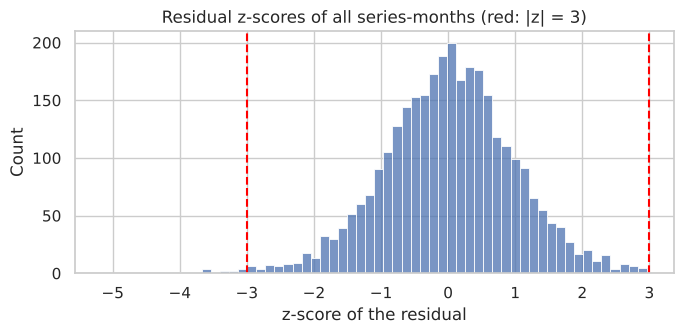

In [12]:
# Distribution of the z-scores: most months are close to 0, anomalies are in the tails
plt.figure(figsize=(7, 3.5))
sns.histplot(panel["z"], bins=60)
for x in (-3, 3):
    plt.axvline(x, color="red", ls="--")
plt.xlabel("z-score of the residual"); plt.title("Residual z-scores of all series-months (red: |z| = 3)")
plt.tight_layout(); plt.savefig(FIG / "02_zscore_hist.png", dpi=200); plt.show()

### 3.1 Explain the anomalies
Ramadan and Hajj follow the lunar Hijri calendar and move ~11 days earlier every
year, so the same Gregorian month can contain them one year and not the next.
For holy-city destinations (Makkah and Madinah provinces) we label such cases
as **calendar shifts** (expected, explainable). 2021 cases are labelled
**COVID-19 period**. Months with fewer than 500 tourists are labelled
**very small count**: the Metadata sheet warns that city-level survey estimates
have a large margin of error, so a jump from 1 to 5,000 visitors is more likely
measurement noise than a real event. The rest are **unexplained** and worth
investigating (possible events, new attractions or reporting changes).

In [13]:
cal = t.calendar_table(panel["date"])
cal_prev = cal.assign(date=cal["date"] + pd.DateOffset(years=1))
panel = panel.merge(cal, on="date", how="left")
shift = (cal.set_index("date")[["ramadan_days", "hajj_days", "prehajj_days"]]
            .sub(cal_prev.set_index("date")[["ramadan_days", "hajj_days", "prehajj_days"]], fill_value=0)
            .abs().sum(axis=1) > 0).rename("calendar_shift")
panel = panel.merge(shift.reset_index(), on="date", how="left")
panel["holy"] = panel["province"].isin(["Makkah", "Madinah"])

def explain(r):
    if r["tourists"] < 500: return "Very small count (survey noise)"
    if r["year"] == 2021: return "COVID-19 period"
    if r["holy"] and (r["calendar_shift"] or r["ramadan_days"] + r["hajj_days"] + r["prehajj_days"] > 0):
        return "Hijri calendar shift"
    return "Unexplained"

flag = panel[panel.anomaly].copy()
flag["explanation"] = flag.apply(explain, axis=1)
flag["direction"] = np.where(flag["residual"] > 0, "higher than expected", "lower than expected")
flag = flag.reindex(flag["z"].abs().sort_values(ascending=False).index)
cols = ["series", "date", "tourists", "z", "direction", "explanation"]
flag[cols].to_csv(OUT / "anomalies.csv", index=False)
print(flag["explanation"].value_counts())
flag[cols].head(15).round({"z": 2})

explanation
Unexplained                        12
Very small count (survey noise)     4
Hijri calendar shift                2
COVID-19 period                     1
Name: count, dtype: int64


,series,date,tourists,z,direction,explanation
2603,Inbound | Arar,2022-12-01,51.0,-5.16,lower than expected,Very small count (survey noise)
3023,Inbound | Other NB,2022-12-01,243.0,-4.29,lower than expected,Very small count (survey noise)
2543,Inbound | Al Qurayyat,2022-12-01,1.0,-4.09,lower than expected,Very small count (survey noise)
2539,Inbound | Al Qurayyat,2022-08-01,1.0,-3.99,lower than expected,Very small count (survey noise)
1277,Domestic | Other Aseer,2022-06-01,86301.0,-3.83,lower than expected,Unexplained
497,Domestic | BILJURASHI,2022-06-01,1219.0,-3.67,lower than expected,Unexplained
137,Domestic | Al Bahah,2022-06-01,25712.0,-3.67,lower than expected,Unexplained
917,Domestic | Khamis Mushait,2022-06-01,52354.0,-3.59,lower than expected,Unexplained
2177,Domestic | Taif,2022-06-01,149640.0,-3.59,lower than expected,Hijri calendar shift
2932,Inbound | Makkah,2025-05-01,42047.0,-3.57,lower than expected,Hijri calendar shift


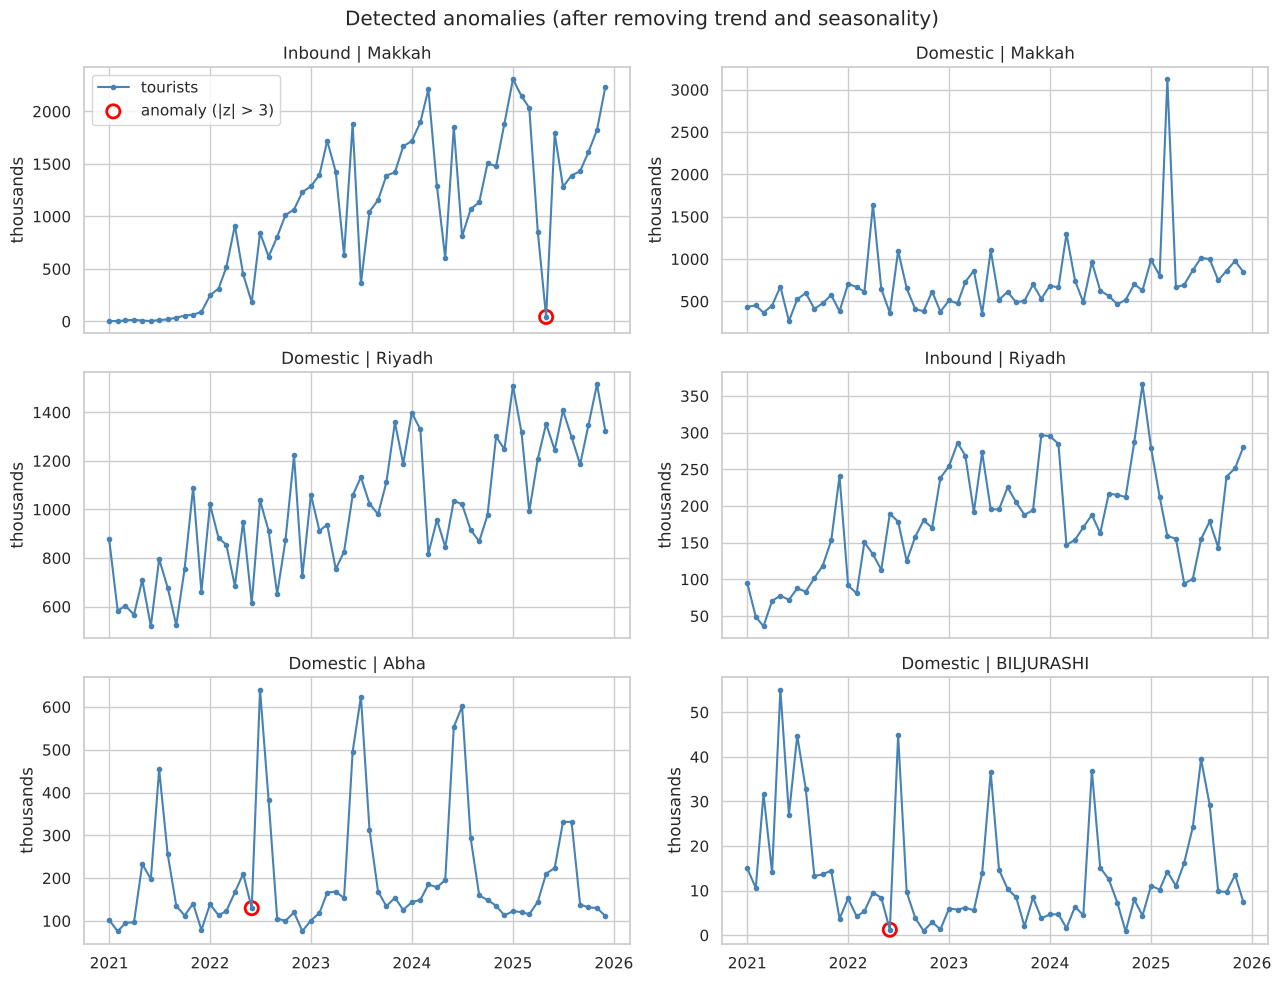

In [14]:
# Visualise anomalies for six important series
show = ["Inbound | Makkah", "Domestic | Makkah", "Domestic | Riyadh",
        "Inbound | Riyadh", "Domestic | Abha", "Domestic | BILJURASHI"]
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
for ax, s in zip(axes.ravel(), show):
    g = panel[panel.series == s]
    ax.plot(g["date"], g["tourists"] / 1e3, color="steelblue", marker=".", label="tourists")
    a = g[g.anomaly]
    ax.scatter(a["date"], a["tourists"] / 1e3, s=90, facecolors="none", edgecolors="red", lw=2,
               label="anomaly (|z| > 3)")
    ax.set_title(s); ax.set_ylabel("thousands")
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0, 0].legend()
plt.suptitle("Detected anomalies (after removing trend and seasonality)")
plt.tight_layout(); plt.savefig(FIG / "02_anomalies_examples.png", dpi=200); plt.show()

In [15]:
# Save the seasonality results for the report
conc.sort_values("cv", ascending=False).to_csv(OUT / "seasonality_concentration.csv", index=False)
print("Saved outputs/seasonality_concentration.csv and outputs/anomalies.csv")

Saved outputs/seasonality_concentration.csv and outputs/anomalies.csv


## 4. Main findings (from the executed outputs above)
**Seasonal concentration**
* **National level:** domestic demand is fairly even and becoming more even every year
  (CV 0.176 in 2023 to 0.107 in 2025, top-3 share 31.6% to 28.5%). Inbound demand is more
  concentrated (CV 0.21-0.30, top-3 share 31-34%, peak/low ratio 4.8 in 2025).
* **Different calendars:** domestic tourism peaks in **June-July** (summer holidays) and
  **November**. Inbound peaks in **December-March** and is lowest in **May**, the pre-Hajj
  month when Umrah is restricted (seasonal index 0.52).
* **Destination level:** the strongest seasonality is in the southern summer resorts.
  Al Bahah (CV 0.85, 58% of tourists in 3 months), Biljurashi, Abha (July index 2.4) and Taif (July 1.9).
  Other Jazan is a winter destination (Nov-Jan), and domestic Makkah peaks in Ramadan (March).
  By province, Albaha (0.76), Aseer (0.43) and Jazan (0.43) are the most concentrated;
  Eastern (0.11) and Riyadh (0.13) are the most balanced.
* **Stability:** for most destinations the busiest month was the same in only 2 of the 4 years
  2022-2025. Peaks move between neighbouring months (e.g. June vs. July, or with Ramadan),
  so planners should think in **peak seasons** rather than one fixed peak month.

**Anomalies**
* 19 of 3,120 series-months (0.6%) have |z| > 3 after removing trend and seasonality.
* Explained cases: very small inbound counts (e.g. 1 tourist in Al Qurayyat, Dec 2022 = survey
  noise), Hijri calendar shifts (Inbound Makkah May 2025: 42,047 tourists vs. about 1.5 M
  in normal months - the whole pre-Hajj period fell in May), and the COVID-19 period.
* **June 2022** was unusually low in eight southern/summer destinations at the same time
  (Abha, Taif, Al Bahah, Biljurashi, Khamis Mushait, Other Aseer, Al Qurayyat, Umluj).
  A shared cause, for example a different timing of the school summer holiday that year,
  is more likely than eight separate events. This should be checked with the data provider.

**Sustainability meaning (SDG 8, 11, 12).** Summer resorts in the south receive a large
share of their yearly visitors in 2-3 months. That leads to crowding, pressure on water and
services, and seasonal jobs. Off-season promotion (e.g. winter events in Abha and Taif) and
capacity planning for the peak seasons above could spread demand more evenly.